Part 1 for Data Cleaning + Part 2 for EDA

Part 1.1
Load data and Inspect

In [2]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv(
    "COVID-19BehaviorData_CAN2022.csv",
    low_memory=False
)

print(df_raw.shape)
display(df_raw.head(10))

(6430, 512)


,RecordNo,endtime,qweek,i1_health,i2_health,i7a_health,i3_health,i4_health,i5_health_1,i5_health_2,...,vac_man_96,vac_man_99,q_other,had_covid,vac_boost_beyond,future_1,future_2,had_covid_2,long_covid,future_3
0,41589,06/01/2022 18:02,week 44,,0,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,41731,03/01/2022 23:48,week 44,,1,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,41756,10/01/2022 04:53,week 44,,0,,,,,,...,Yes,No,"Oui bar , restaurent",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,41846,01/01/2022 13:15,week 44,,5,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,41847,01/01/2022 19:12,week 44,,150,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,41867,01/01/2022 15:21,week 44,,4,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,41868,01/01/2022 20:02,week 44,,14,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,41920,02/01/2022 12:36,week 44,,0,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,41937,01/01/2022 00:11,week 44,,0,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,41951,01/01/2022 00:43,week 44,,5,,,,,,...,No,No,__NA__,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Part 1.2 
Missing value determination

In [3]:
df_raw = df_raw.replace(r"^\s*$", np.nan, regex=True)

missing = df_raw.isna().mean() * 100

display(missing.sort_values(ascending=False).head(15))

ct8_6        100.0
ct5_2        100.0
ct7_2        100.0
ct7_1        100.0
ct6_other    100.0
ct6_99       100.0
ct6_96       100.0
ct6_6        100.0
ct6_5        100.0
ct6_4        100.0
ct6_3        100.0
ct6_2        100.0
ct6_1        100.0
ct5_other    100.0
ct5_99       100.0
dtype: float64

Part 1.3
Select our target(i9_health) and predictors(15 vars)

In [4]:
target = "i9_health"

num_cols = [
    "age",
    "cantril_ladder"
]

cat_cols = [
    "gender",
    "region",
    "household_size",
    "household_children",
    "employment_status",
    "qweek",
    "PHQ4_1",
    "PHQ4_3",
    "vac2_1",
    "vac2_2",
    "vac7",
    "WCRex1",
    "Vent_3"
]

features = num_cols + cat_cols

df_clean = df_raw[[target] + features].copy()

for col in num_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
)

print("Selected predictors:", len(features))
display(df_clean.head())

Selected predictors: 15


,i9_health,age,cantril_ladder,gender,region,household_size,household_children,employment_status,qweek,PHQ4_1,PHQ4_3,vac2_1,vac2_2,vac7,WCRex1,Vent_3
0,Yes,52,9,Female,Quebec / Québec,4,0,Full time employment,week 44,Not at all,Not at all,5 – Strongly disagree,5 – Strongly disagree,Very much,Somewhat well,Always
1,No,51,6,Female,British Columbia / Colombie Britanique,2,0,Full time employment,week 44,Several days,More than half the days,1 - Strongly agree,2,Moderately,Very well,Always
2,No,57,1,Female,Quebec / Québec,1,0,Part time employment,week 44,Nearly every day,Not at all,5 – Strongly disagree,5 – Strongly disagree,Very much,Very well,Not at all
3,Yes,64,6,Female,Quebec / Québec,1,0,Retired,week 44,More than half the days,More than half the days,1 - Strongly agree,1 - Strongly agree,Moderately,Very badly,Always
4,Yes,45,5,Male,Quebec / Québec,5,5 or more,Full time employment,week 44,Not at all,Not at all,1 - Strongly agree,5 – Strongly disagree,Very much,Somewhat well,Always


Part 1.4 For Data Encoding & Scaling rules future Modeling
- Age、Cantril Ladder：Scaling
- Gender、Region、Employment：One-Hot Encoding。
- PHQ4：先检查其有序性质，再决定保留 One-Hot 还是 Ordinal Encoding。
- Vac2 变量：需要核查问卷编码后决定。
- 缺失值：训练数据中的数值和类别变量分别采用适当的填补方法。

Part 1.5 Train/Test Split in case for "Test Set Leakage"

In [6]:
from sklearn.model_selection import train_test_split

# Keep only Yes and No responses
model_df = df_clean[
    df_clean["i9_health"].isin(["Yes", "No"])
].copy()

# Create binary target: No = 1, Yes = 0
model_df["target"] = model_df["i9_health"].map({
    "Yes": 0,
    "No": 1
})

# Split data once (80% training, 20% testing)
train_df, test_df = train_test_split(
    model_df,
    test_size = 0.2,
    random_state = 5,
    stratify=model_df["target"]
)

# Prepare X and y for later modeling
X_train = train_df[features]
X_test = test_df[features]

y_train = train_df["target"]
y_test = test_df["target"]

# Check results
print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

print("\nTraining target distribution:")
print(train_df["i9_health"].value_counts(normalize=True))

print("\nTest target distribution:")
print(test_df["i9_health"].value_counts(normalize=True))

Training set: (4729, 17)
Test set: (1183, 17)

Training target distribution:
i9_health
Yes    0.78875
No     0.21125
Name: proportion, dtype: float64

Test target distribution:
i9_health
Yes    0.788673
No     0.211327
Name: proportion, dtype: float64


Part 2.1
# Target Distribution
    Purpose: Checking if there is any Class Imbalance for Training Set and Target Distribution

i9_health
Yes    3730
No      999
Name: count, dtype: int64
i9_health
Yes    78.875026
No     21.124974
Name: proportion, dtype: float64


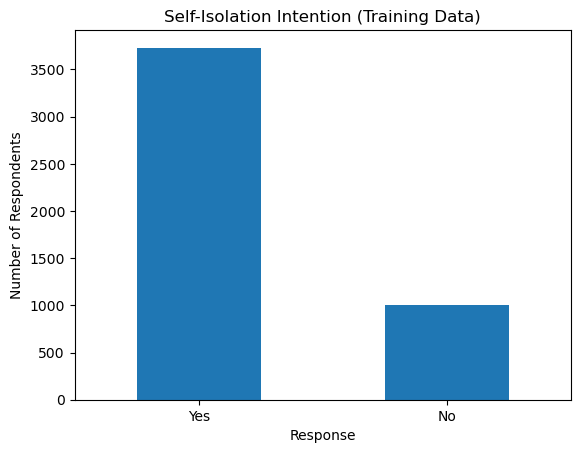

In [8]:
import matplotlib.pyplot as plt

# Target counts
print(train_df["i9_health"].value_counts())

# Target percentages
print(train_df["i9_health"].value_counts(normalize=True) * 100)

# Bar chart
train_df["i9_health"].value_counts().plot(kind="bar")

plt.title("Self-Isolation Intention (Training Data)")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)
plt.show()

Part 2.2
# Region & Target Summary
    Purpose: Sample size Visualization & Self-Isolation Intention by region

In [26]:
region_summary = pd.crosstab(
    train_df["region"],
    train_df["i9_health"]
)

region_summary["Total"] = region_summary.sum(axis=1)
region_summary["No Rate"] = (
    region_summary["No"] / region_summary["Total"] * 100
)

display(region_summary.sort_values("No Rate", ascending=False))

i9_health,No,Yes,Total,No Rate
region,,,,
New Brunswick / Nouveau-Brunswick,27,89,116,23.275862
Quebec / Québec,272,920,1192,22.818792
British Columbia / Colombie Britanique,137,479,616,22.240260
Yukon,2,7,9,22.222222
Ontario,366,1362,1728,21.180556
Manitoba,37,146,183,20.218579
Alberta,101,424,525,19.238095
Newfoundland & Labrador / Terre-Neuve-et-Labrador,11,57,68,16.176471
Nova Scotia / Nouvelle-Écosse,19,100,119,15.966387


Part 2.3
# Categorical variable Vs. Target 
# Government Performance vs Self-Isolation Intention
    Purpose: Examine whether respondents' evaluations of government pandemic management are associated with self-isolation intention.

i9_health,No,Yes
WCRex1,,
Don't know,0.301205,0.698795
Somewhat badly,0.218530,0.781470
Somewhat well,0.170181,0.829819
Very badly,0.314917,0.685083
Very well,0.159744,0.840256


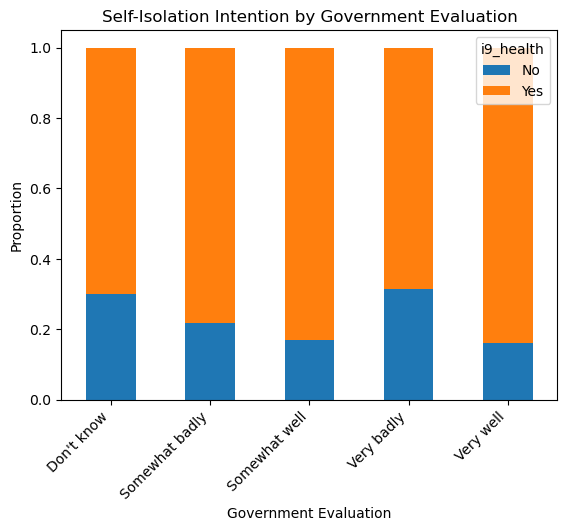

In [9]:
# Crosstab: counts
government_pct = pd.crosstab(
    train_df["WCRex1"],
    train_df["i9_health"],
    normalize="index"
)

display(government_pct)

government_pct.plot(kind="bar", stacked=True)

plt.title("Self-Isolation Intention by Government Evaluation")
plt.xlabel("Government Evaluation")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.show()

# Social Contact Avoidance vs Self-Isolation Intention
    Purpose: Examine how recent preventive behavior relates to willingness to self-isolate.

i9_health,No,Yes
Vent_3,,
Always,0.161198,0.838802
Frequently,0.153299,0.846701
Not at all,0.401739,0.598261
Rarely,0.278325,0.721675
Sometimes,0.240000,0.760000


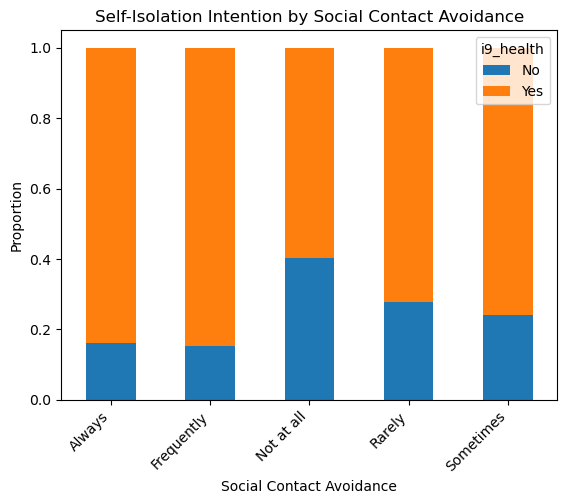

In [10]:
vent_pct = pd.crosstab(
    train_df["Vent_3"],
    train_df["i9_health"],
    normalize="index"
)

display(vent_pct)

vent_pct.plot(kind="bar", stacked=True)

plt.title("Self-Isolation Intention by Social Contact Avoidance")
plt.xlabel("Social Contact Avoidance")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.show()

# Survey Week vs Self-Isolation Intention
    Purpose: Investigate whether self-isolation intentions differ across survey weeks.

qweek
week 44    482
week 45    751
week 46    727
week 47    674
week 48    660
week 49    724
week 50    711
Name: count, dtype: int64


i9_health,No,Yes
qweek,,
week 44,0.149378,0.850622
week 45,0.158455,0.841545
week 46,0.163686,0.836314
week 47,0.221068,0.778932
week 48,0.207576,0.792424
week 49,0.263812,0.736188
week 50,0.298172,0.701828


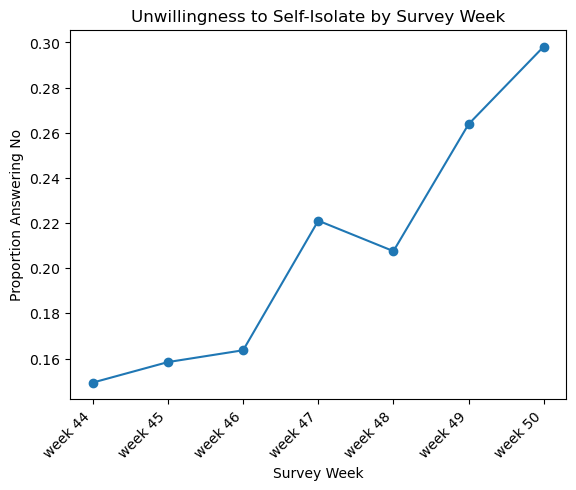

In [14]:
# sample size by week for qweek
print(train_df["qweek"].value_counts().sort_index())

week_pct = pd.crosstab(
    train_df["qweek"],
    train_df["i9_health"],
    normalize="index"
)

display(week_pct)

week_pct["No"].plot(kind="line", marker="o")

plt.title("Unwillingness to Self-Isolate by Survey Week")
plt.xlabel("Survey Week")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Proportion Answering No")
plt.show()

Part 2.4
# Numeric Distributions
    Purpose: Checking the distribution for numerical variables to find any outliers or skews

               age  cantril_ladder
count  4729.000000     4729.000000
mean     50.228801        6.261155
std      17.973816        2.096472
min      18.000000        0.000000
25%      35.000000        5.000000
50%      51.000000        7.000000
75%      66.000000        8.000000
max      90.000000       10.000000


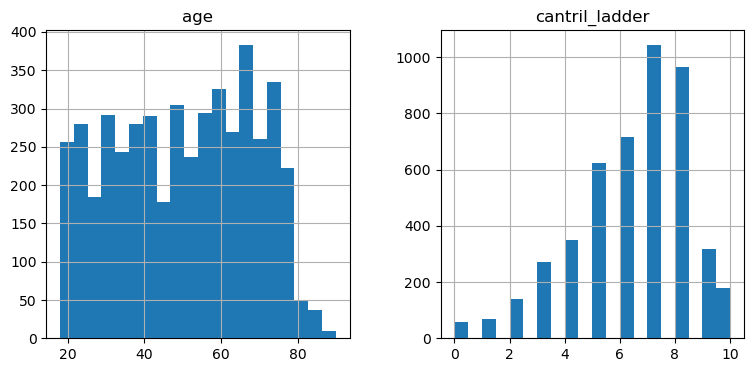

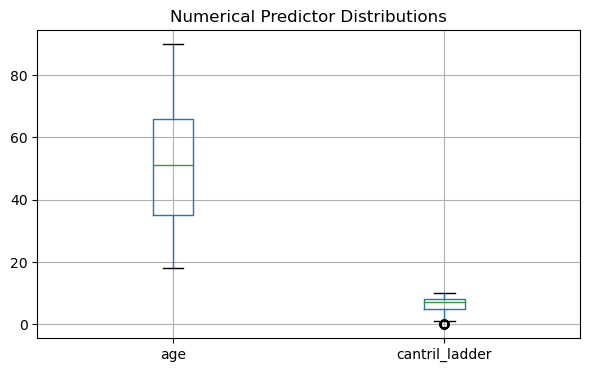

In [15]:
# Summary statistics
print(train_df[num_cols].describe())

# Histograms
train_df[num_cols].hist(
    bins=20,
    figsize=(9, 4)
)

plt.show()

# Boxplots
train_df[num_cols].boxplot(figsize=(7, 4))

plt.title("Numerical Predictor Distributions")
plt.show()

Part 2.5
# Numeric Predictors Vs. Target
    Purpose: Checking if there is diff age distribution within Target variable

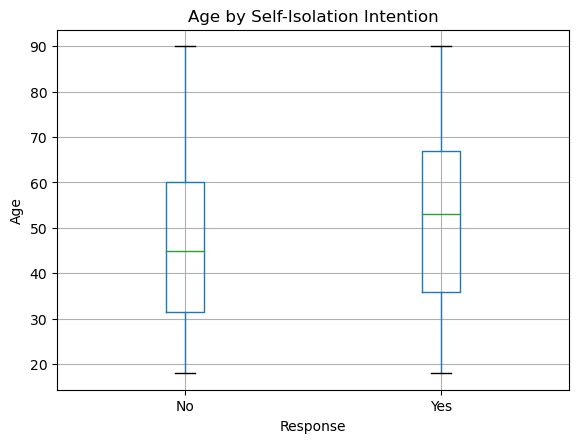

In [16]:
# Age by target
train_df.boxplot(
    column="age",
    by="i9_health"
)

plt.title("Age by Self-Isolation Intention")
plt.suptitle("")
plt.xlabel("Response")
plt.ylabel("Age")
plt.show()

i9_health        No       Yes
age_group                    
18-29      0.258794  0.741206
30-44      0.270370  0.729630
45-59      0.227605  0.772395
60+        0.143263  0.856737


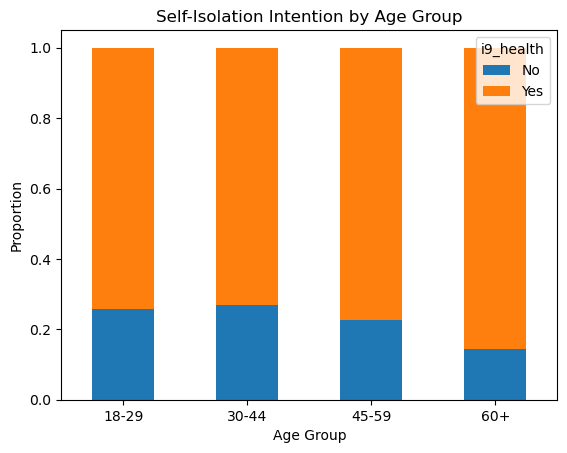

In [17]:
# Create age groups
train_df = train_df.copy()

train_df["age_group"] = pd.cut(
    train_df["age"],
    bins=[17, 29, 44, 59, 120],
    labels=["18-29", "30-44", "45-59", "60+"]
)

# Normalized crosstab
age_pct = pd.crosstab(
    train_df["age_group"],
    train_df["i9_health"],
    normalize="index"
)

print(age_pct)

age_pct.plot(kind="bar", stacked=True)

plt.title("Self-Isolation Intention by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.show()

Part 2.6
# Multivariate Analysis
# Age x Life satisfaction -> No Rate
    Purpose: Investigate the relationship b/w Age & Life Satisfaction after the combination

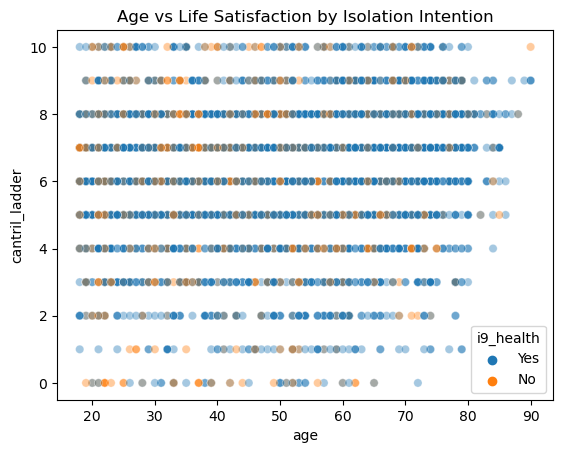

In [18]:
import seaborn as sns

sns.scatterplot(
    data=train_df,
    x="age",
    y="cantril_ladder",
    hue="i9_health",
    alpha=0.4
)

plt.title("Age vs Life Satisfaction by Isolation Intention")
plt.show()

The scatter plot examines the relationship between age, life satisfaction, and self-isolation intention.

There is substantial overlap between respondents who answered "Yes" and "No" across different ages and life satisfaction scores. No clear separation between the two groups is visible.

This suggests that age and life satisfaction alone may not be sufficient to distinguish respondents' self-isolation intentions. However, overlapping points make it difficult to assess the strength of their relationship visually.

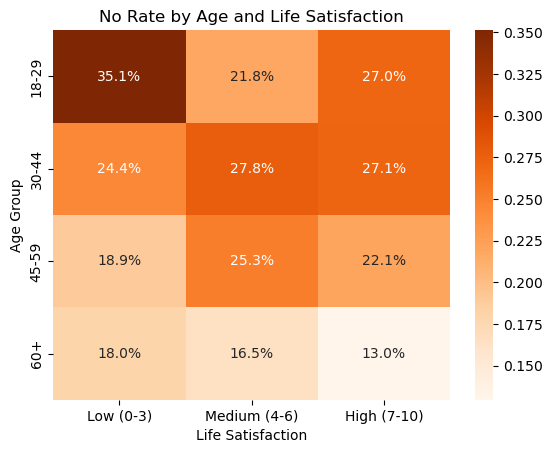

In [19]:
# Create age groups
train_df["age_group"] = pd.cut(
    train_df["age"],
    bins=[17, 29, 44, 59, 120],
    labels=["18-29", "30-44", "45-59", "60+"]
)

# Create life satisfaction groups
train_df["satisfaction_group"] = pd.cut(
    train_df["cantril_ladder"],
    bins=[-1, 3, 6, 10],
    labels=["Low (0-3)", "Medium (4-6)", "High (7-10)"]
)

# Calculate proportion answering No
heatmap_data = train_df.pivot_table(
    index="age_group",
    columns="satisfaction_group",
    values="target",
    aggfunc="mean",
    observed=True
)

# Plot heatmap
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1%",
    cmap="Oranges"
)

plt.title("No Rate by Age and Life Satisfaction")
plt.xlabel("Life Satisfaction")
plt.ylabel("Age Group")
plt.show()

# Government Evaluation × Social Contact Avoidance → No Rate
    Purpose: Explore whether self-isolation intention varies across combinations of government evaluation and preventive behavior.

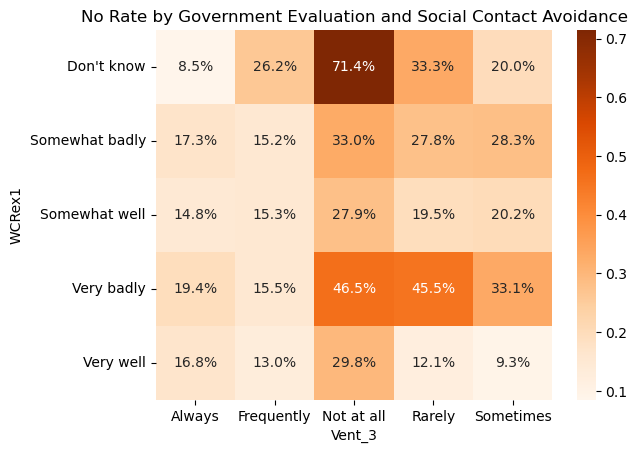

In [29]:
# No = 1, Yes = 0 (already defined)
multi = train_df.pivot_table(
    index="WCRex1",
    columns="Vent_3",
    values="target",
    aggfunc="mean"
)

sns.heatmap(
    multi,
    annot=True,
    fmt=".1%",
    cmap="Oranges"
)

plt.title("No Rate by Government Evaluation and Social Contact Avoidance")
plt.show()

In [ ]:
# checking smaple size for corss table in case of small sample size
pd.crosstab(
    train_df["WCRex1"],
    train_df["Vent_3"]
)

Vent_3,Always,Frequently,Not at all,Rarely,Sometimes
WCRex1,,,,,
Don't know,47,42,35,12,30
Somewhat badly,231,330,112,108,212
Somewhat well,615,803,111,154,356
Very badly,211,187,260,99,148
Very well,298,184,57,33,54


Part 2.7
# Correlation Analysis
    Purpose: Checking any correlation and duplicate information b/w numerical variables

                     age  cantril_ladder
age             1.000000        0.168678
cantril_ladder  0.168678        1.000000


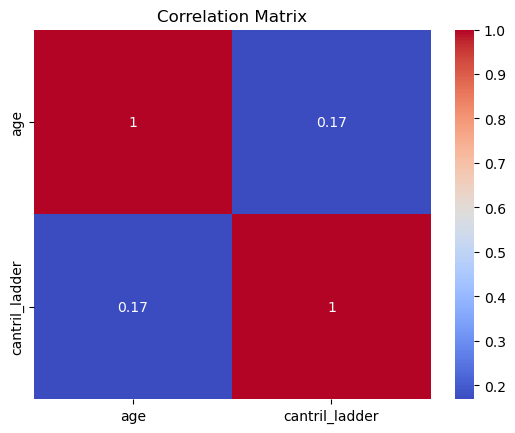

In [23]:
# Correlation table
corr = train_df[num_cols].corr()

print(corr)

# Heatmap
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()